# Test 1 de modélisation numérique 2024 - semaine 7

### Instructions:

- L'examen dure 2 h 30.
- Ce document contient une figure qui devrait s'afficher dans le notebook (pour cela, assurez-vous d'avoir copié-collé également le répertoire 'fig' de 'Données Examen'). 
- Vous pouvez vous référer à au document 'Introduction à Python pour le cours de modélisation numérique' disponible dans le répertoire 'Données Examen'.
- Assurez-vous d'exécuter l'intégralité de votre script pour garantir son bon fonctionnement.
- À la fin du test, rendez votre fichier "Nom_Prenom_test1.ipynb" en le déposant dans le sous-dossier à votre nom, dans le dossier de votre salle, dans le dossier "Dépôt Copies":

```bash
"Dépot copies"
├── env-2113
│   ├── Nom1
│   ├── Nom2
|   -...
├── env-2138
│   ├── Nom1
│   ├── Nom2
|   -...
├── env-2145
│   ├── Nom1
│   ├── Nom2
|   -...
├── env-2153
│   ├── Nom1
│   ├── Nom2
|   -...
├── geo-2145
│   ├── Nom1
│   ├── Nom2
|   -...
```



# ́Température dans le sol à Seattle

Le but de cet exercice est de modéliser l'évolution de la température dans le sol à un site particulier de Seattle, une ville située au Nord-Ouest des Etats-Unis, jusqu'à une profondeur de 30 m, comme illustré sur la figure ci-dessous. La température \(T(t,z)\) est ici une fonction du temps \(t\) (en années) et de la profondeur \(z\) (en mètres). La température initiale est de 10 °C sur toute la profondeur :

\begin{equation*} 
T(0,z) = 10^{\circ} C. \qquad (1)
\end{equation*}

A la surface ($z=30$ m), la température est donnée par la fonction suivante (condition de Dirichlet):

\begin{equation*} 
T (t,30) = - 2 - 10 \cos(2 \pi t), \qquad (2)
\end{equation*}

de sorte que la température oscille entre -12°C et 8°C au rythme des saisons. A la profondeur de 30 m ($z=0$), nous supposons qu'aucun flux de chaleur n'est possible à aucun moment (condition de Neumann): 

\begin{equation*} 
\frac{\partial T}{\partial z}(t,0) = 0. \qquad (3)
\end{equation*}

En plus des conditions de bord ci-dessus, on suppose la présence d'une conduite d'eau à une profondeur de 8 m sous la surface du sol ($z=22$ m), qui est active (alimentée en eau à 15°C) entre les temps $t_1=2$ ans et $t_2=7$ ans: 

\begin{equation*}
T (t,22) = 15^{\circ} C, \quad {\rm si} \quad t_1 \le t \le t_2. \qquad (4)
\end{equation*}
 
<div style="text-align: center;">
    <img src="fig/scheme.png" alt="Scheme" style="width: 50%;" />
</div>

*Figure 1 : Géométrie du site à modéliser, incluant le bord inférieur du domaine (z = 0 m), la ligne de contrôle de la température (z = 10 m), la conduite d'eau (z = 22 m), ainsi que la surface terrestre (z = 30 m) où différentes conditions s'appliquent. La diffusivité varie dans la question 1 (une seule diffusivité pour une seule couche de sédiments) et la question 2 (deux diffusivités pour une couche de sédiments et une couche de rocher avec une transition à z = 20 m).*
 
Vous allez construire un modèle numérique qui simule l'évolution de la température dans le sol de \(z = 0\) m à \(z = 30\) m pendant 100 ans, en partant de \(t = 0\). Le but sera de prédire quand la température à une profondeur de 20 m (ligne de contrôle, z = 10 m) passe en dessous d'un certain seuil.
 
Le modèle numérique sera basé sur la loi de Fourier pour le flux de température \(q\) en fonction de la diffusivité \(D\), de la température \(T\) et de la distance verticale \(z\) :

\begin{equation*} 
  q = -D \frac{\partial T}{dz}, \qquad (5)
\end{equation*}

ainsi que l'équation traduisant la conservation de l'énergie:

\begin{equation*}
  \frac{\partial T}{\partial t} = -\frac{\partial q}{\partial z}. \qquad (6)
\end{equation*}

Les deux équations doivent être discrétisées et implémentées dans un modèle numérique qui décrit l'évolution temporelle de la température du sol \(T\), en se basant sur les paramètres donnés dans la table ci-dessous.

## Q1: Une seule couche de sédiments

Dans un premier temps, nous supposons que le sol est homogène (composé de sédiments uniquement) avec un coefficient de diffusion $D = D_{sed}$. Implémentez le modèle numérique en prenant la forme discrétisée des équations (5)-(6), les conditions aux bords (2)-(3), la condition initiale (1), et la contrainte imposée par la conduite d'eau (4). Vous pouvez définir le pas de temps avec $dt = dz^2 / (2.1 \times D_{sed})$, ce qui assure la stabilité de la méthode numérique.

**Note :** Contrairement à ce que l'on a vu jusqu'à présent, la condition de bord en surface (2) dépend du temps. Il faut donc bien veiller à la mettre à jour dans la boucle. Si vous n'arrivez pas à l'implémenter correctement, implémentez la condition plus simple $T(t,30) = -2°C$ afin que vous puissiez continuer l'exercice.

**Question 1** : Combien de temps s'écoule-t-il jusqu'à ce que la température à la ligne de contrôle (z = 10 m) enregistre une température inférieure à une valeur seuil de 8 °C ?

Illustrez vos résultats graphiquement dans une figure annotée qui affiche la température $T$ en fonction de la position vertical $z$ (avec noms pour les axes, titre avec le temps affiché, axes fixes, etc.), et faites en sorte que votre code s'arrête lorsque le seuil est atteint.


| **Paramètres**                                          | **Nom Python** | **Valeurs**                                 |
|---------------------------------------------------------|----------------|---------------------------------------------|
| Altitude de la surface                                  | zsurf          | 30 m                                        |
| Altitude de la conduite d'eau                           | zcond          | 22 m                                        |
| Altitude de la ligne de contrôle                        | zcont          | 10 m                                        |
| Altitude du bord inférieur du modèle                    | zbase          | 0 m                                         |
| Température initiale                                    | Tinit          | 10 °C                                       |
| Température de la conduite d'eau (quand active)         | Tcond          | 15 °C                                       |
| Temps activation de la conduite d'eau                   | t1             | 2 ans                                       |
| Temps de-activation de la conduite d'eau                | t2             | 7 ans                                       |
| Diffusivité de la couche sédimentaire $D_{sed}          | Dsed           | 15 m²/an                                    |
| Nombre de cellules recommandé                           | nz             | 101                                         |
| Temps total                                             | ttotal         | 100 ans                                     |
| Seuil température                                       | Tseuil         | 8 °C                                        |

**Table 1: Paramètres du modèle pour les question 1.** 

## Q2:  Deux couches (sédiments et rocheuse)

Pour la deuxième question, adaptez le code en introduisant un paramètre Q qui vaut 1 ou 2, afin que le code fonctionne pour pour les deux questions en choissant `Q=1`ouu `Q=2` (Si vous rencontrez un problème avec cela, vous avez toujours la possibilité de créer un nouveau bloc, copier-coller votre code de la premiere partie et l'adapter pour la question 2).

Pour cette question, au lieu d'une diffusivité $D$ homogène/constante dans l'espace, celle-ci a deux valeurs de $D$ différentes: $ D_{sed} = 15 $ m²/an au-dessus $z_{lim}=20$ m pour la couche de sédiments en haut et $ D_{roch} = 30 $ m²/an  au-dessous $z_{lim}=20$ m pour la couche rocheuse en bas. 

**Note:** prenez bien en compte pour modifier le code que $D$ est maintenant un vecteur après discrétisation, ainsi que l'adaptation du pas de temps : $ dt = dz^2 / (2.1 \times max( D_{sed}, D_{roc})) $. Attention à ce que le vecteur $D$ ait la bonne dimension.


**Question 2** : Comme dans la question 1, combien de temps s'écoule-t-il jusqu'à ce que la température à la ligne de contrôle (z = 10 m) enregistre une température inférieure à une valeur seuil de 8 °C ?

### ✅ **À vous de faire !** 

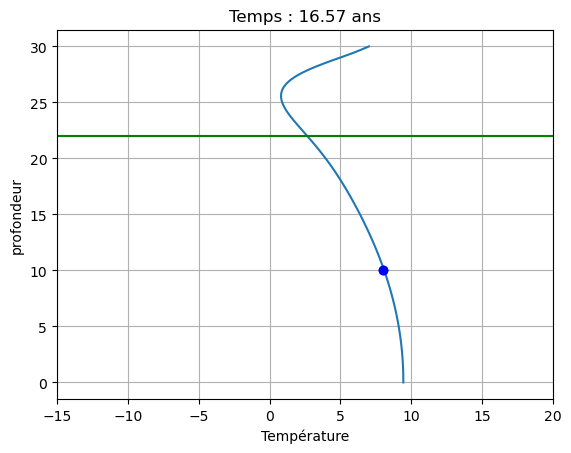

La température a dépassé pour la première fois 8 °C à une profondeur 10 m après 16.85 ans.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import clear_output, display

# Code version
Q = 1

# Physical parameters
Dsed = 15       # diffusivite (m2/an)
Droch = 30      # diffusivité (m2/an)
zsurf = 30      # alt surface
zcond = 22      # alt conduite d'eau
zcont = 10      # alt ligne de controle
zbase = 0       # bord inférieur du modèle
zlim = 20       # limite de couches
Tinit = 10      # température initiale
Tcond = 15      # température de la conduite
Tseuil = 8      # température seuil
Tbase = 0       # température à la abse (flux nul)
t1 = 2          # temps d'activation conduite
t2 = 7          # temps déactivation conduite
ttot = 100      # temps total

# Numerical parameters
nz = 101                         # nombre de cellules
dz = zsurf / (nz - 1)            # taille d'une cellule
z = np.linspace(zbase, zsurf, nz)    # coordonees des point du maillage
nout = 100                       # afficher la figure chaque 100e step

# conditions selon Q
if Q == 1:
    D = Dsed
    dt = dz**2 / (2.1 * Dsed)        # condition sur le pas de temps
elif Q == 2:
    D = np.ones(nz-1) * Dsed
    D[:int(zlim/dz)] = Droch
    dt = dz**2 / (2.1 * max(Dsed, Droch))
    
nt = int(ttot/dt)                # nombre de pas de temps

# Initial conditions
T = np.ones(nz) * Tinit
time = 0

# create the figure outside the loop 
fig, ax = plt.subplots()
 
# time loop
for it in range(1, nt):
    time += dt    # update time
    # Conditions de bord
    T[-1] = -2-(10 * np.cos(2*np.pi*time))
    T[0] = T[1]
    # Implémentation du conduit
    if time >= t1 and time <= t2:
        T[int(zcond/dz)] = 15

    # Mettre a jour le flux q en fonction de C 
    q = - D * ( T[1:] - T[:-1] ) / dz   
    # Mettre a jour dCdt
    dTdt = - ( q[1:] - q[:-1] ) / dz
    # Mettre a jour C
    T[1:-1] += dTdt * dt

    if T[int(zcont/dz)] < Tseuil:
        tpassage = time
        break
 
    # plot
    if it % nout == 0:
        clear_output(wait=True) 
        ax.cla() 
        ax.plot(T, z)
        ax.set_title('Temps : ' + str(round(time, 2)) + ' ans')
        ax.set_xlim(-15, 20)
        ax.plot([Tseuil, Tseuil], [zcont, zcont], 'bo')
        if Q == 2:
            ax.plot([-15, 20], [zlim, zlim], 'r')
        ax.plot([-15, 20], [zcond, zcond], color='green')
        ax.set_xlabel('Température')
        ax.set_ylabel('profondeur')
        ax.grid(True)
        display(fig)
        plt.pause(0.1)

print(f'La température a dépassé pour la première fois {Tseuil} °C à une profondeur {zcont} m après {round(tpassage, 2)} ans.')